# Lab 1 — CNN on CIFAR-10 (PyTorch)

Conv -> ReLU -> Pool layers + fully connected classifier.

In [1]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
print('torch', torch.__version__, ' device', device)

torch 2.14.1  device mps


## 1. CNN: Conv -> ReLU -> Pool + FC classifier

In [2]:
class CNN(nn.Module):
    def __init__(self, in_channels=3, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            # conv -> relu -> pool
            nn.Conv2d(in_channels, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),                     # 32x32 -> 16x16

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),                     # 16x16 -> 8x8
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


model = CNN().to(device)
print('forward shape:', model(torch.randn(8, 3, 32, 32, device=device)).shape)
print('parameters  :', sum(p.numel() for p in model.parameters()))

forward shape: torch.Size([8, 10])
parameters  : 545098


## 2. CIFAR-10 data

In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

train_ds = datasets.CIFAR10('./data', train=True,  download=True, transform=transform)
test_ds  = datasets.CIFAR10('./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)
test_loader  = DataLoader(test_ds,  batch_size=512)

x0, y0 = train_ds[0]
print('classes:', train_ds.classes)
print('train samples:', len(train_ds), ' test samples:', len(test_ds))
print('feature shape:', x0.shape, ' label:', y0, ' dtype:', x0.dtype)

classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
train samples: 50000  test samples: 10000
feature shape: torch.Size([3, 32, 32])  label: 6  dtype: torch.float32


## 3. Training loop

In [4]:
model = CNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9)

epochs = 10
train_losses, test_losses, test_accs = [], [], []

for epoch in range(epochs):
    model.train()
    total, count = 0.0, 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()
        total += loss.item() * xb.size(0)
        count += xb.size(0)
    train_losses.append(total / count)

    model.eval()
    tloss, tacc, tcount = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in test_loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            tloss += criterion(logits, yb).item() * xb.size(0)
            tacc += (logits.argmax(1) == yb).sum().item()
            tcount += xb.size(0)
    test_losses.append(tloss / tcount)
    test_accs.append(tacc / tcount)
    print(f'epoch {epoch+1:2d}  train_loss {train_losses[-1]:.4f}  '
          f'test_loss {test_losses[-1]:.4f}  test_acc {test_accs[-1]:.4f}')

epoch  1  train_loss 1.4510  test_loss 1.1255  test_acc 0.6008


epoch  2  train_loss 0.9913  test_loss 0.9423  test_acc 0.6722


epoch  3  train_loss 0.8161  test_loss 0.9032  test_acc 0.6976


epoch  4  train_loss 0.6674  test_loss 0.8985  test_acc 0.6991


epoch  5  train_loss 0.5349  test_loss 0.9613  test_acc 0.6910


epoch  6  train_loss 0.4220  test_loss 1.0807  test_acc 0.6945


epoch  7  train_loss 0.3350  test_loss 1.1674  test_acc 0.6989


epoch  8  train_loss 0.2706  test_loss 1.3540  test_acc 0.6807


epoch  9  train_loss 0.2335  test_loss 1.5139  test_acc 0.6884


epoch 10  train_loss 0.2030  test_loss 1.5548  test_acc 0.6884


## 4. Loss curves

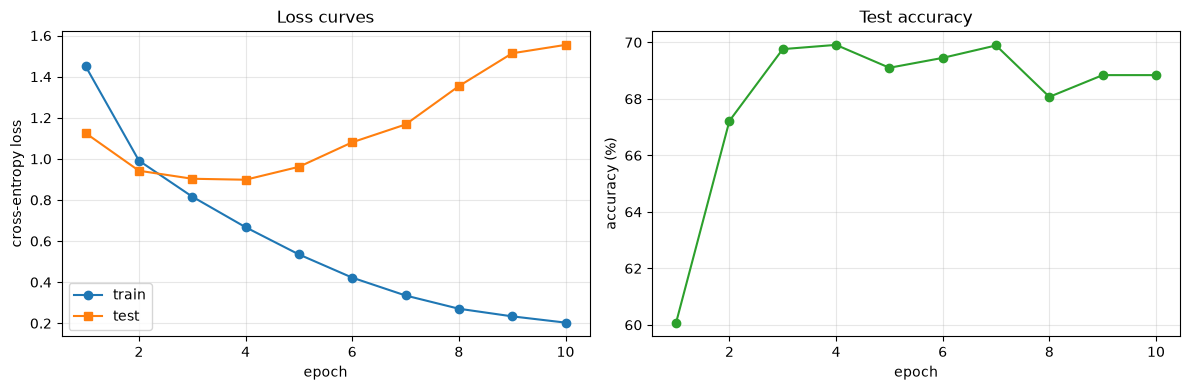

final test accuracy: 68.8%


In [5]:
%matplotlib inline
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(range(1, epochs+1), train_losses, marker='o', label='train')
axes[0].plot(range(1, epochs+1), test_losses,  marker='s', label='test')
axes[0].set_xlabel('epoch')
axes[0].set_ylabel('cross-entropy loss')
axes[0].set_title('Loss curves')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(range(1, epochs+1), [a*100 for a in test_accs], marker='o', color='tab:green')
axes[1].set_xlabel('epoch')
axes[1].set_ylabel('accuracy (%)')
axes[1].set_title('Test accuracy')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()
print(f'final test accuracy: {test_accs[-1]*100:.1f}%')